# Experiment B2 — steps-to-target vs batch size (tuned per method)

This notebook reproduces the *critical-batch-size* view of Figure 1 in `new_setting.png`.

Instead of fixing the compute budget $D$ and reading off the final loss, we fix a **target excess loss** and measure, for each batch size $B$, the **number of optimizer steps $K$ needed to first reach that target**. For every $(\text{method}, B)$ we tune the step size $\eta$ and (for momentum methods) the momentum $\rho$ on a small grid and keep the configuration that reaches the target in the *fewest* steps — matching the paper's "after tuning hyperparameters for each method".

The dashed reference line is $K \propto 1/B$ (perfect linear scaling / iso-compute). Curves that hug it are in the linear-scaling window; where a curve peels off and flattens is its **critical batch size**.

This first pass is the **fast, coarse-grid validation** for the fast-decaying spectrum ($a=\beta=2$), single panel. Widen the grids / raise `DIM`, `N_SEEDS` for a paper-quality run, and add a second panel with $\beta=0.9$ for the slow-decaying regime.

In [4]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# --- problem spectrum (a = BETA; fast-decaying = 2) ---
BETA = 2          # power-law spectrum exponent 'a' in the paper
SIGMA = 1
DIM = 4096        # coarse: 1024 (paper-quality: 2048-4096)
S_VALUE = 1       # source-condition smoothness

# --- measurement ---
TARGET_LOSS = 0.006  # ~100x reduction from E_0~=0.6; deep enough to expose the 1/B window (paper a=2 uses 0.0071)
K_MAX = 60000       # step cap; too small clips the small-B linear regime into a fake elbow
N_SEEDS = 3         # coarse: 3 (paper-quality: 5)
CHUNK = 2048        # minibatch chunking so large B never materializes a full (B, DIM) matrix

# --- per-(method, B) tuning grids ---
ETA_GRID = [0.05, 0.1, 0.2, 0.4, 0.8]
ONE_MINUS_RHO_GRID = [0.2, 0.1, 0.05, 0.01, 0.005, 0.001]   # rho in {0.5, 0.8, 0.95, 0.99}; SGD forces rho=0

# --- batch grid (paper right panel: 2^0 .. 2^10) ---
B_EXPONENTS = list(range(1, 9))
B_LIST = [2 ** e for e in B_EXPONENTS]

ALGOS = {'HB': 'hb', 'Nesterov': 'nag', 'SGD': 'sgd'}

LOAD_CACHE = True
SAVE_CACHE = True
RESULT_DIR = Path('results')
RESULT_DIR.mkdir(exist_ok=True)

print(f'beta(a)={BETA}, sigma={SIGMA}, dim={DIM}, s={S_VALUE}')
print(f'target loss={TARGET_LOSS}, K_max={K_MAX}, seeds={N_SEEDS}')
print(f'batch grid: 2^{B_EXPONENTS[0]} .. 2^{B_EXPONENTS[-1]} ({len(B_LIST)} values)')
print(f'tuning grid: {len(ETA_GRID)} eta x {len(ONE_MINUS_RHO_GRID)} (1-rho) for momentum, {len(ETA_GRID)} eta for SGD')

beta(a)=2, sigma=1, dim=4096, s=1
target loss=0.006, K_max=60000, seeds=3
batch grid: 2^1 .. 2^8 (8 values)
tuning grid: 5 eta x 6 (1-rho) for momentum, 5 eta for SGD


In [5]:
def build_problem(dim=DIM, beta=BETA, s=S_VALUE):
    """Return (lam, theta_star) for the diagonal linear-regression problem."""
    j = np.arange(1, dim + 1, dtype=np.float64)
    lam = j ** (-beta)
    var_star = j ** (-(1.0 + (s - 1.0) * beta))
    theta_star = np.sqrt(var_star)
    return lam, theta_star


def excess_loss(delta, lam):
    """Exact population excess loss E = 1/2 * sum_j lam_j * delta_j^2."""
    return 0.5 * np.sum(lam * delta * delta)


def grad_delta_chunked(delta, B, lam, sigma=SIGMA, rng=None, chunk=CHUNK):
    """Exact stochastic minibatch gradient without materializing a full (B, DIM) batch."""
    rng = rng or np.random.default_rng()
    d = lam.shape[0]
    sqrt_lam = np.sqrt(lam)
    grad = np.zeros(d, dtype=np.float64)
    remaining = int(B)
    while remaining > 0:
        b = min(chunk, remaining)
        X = rng.standard_normal((b, d)) * sqrt_lam
        eps = rng.standard_normal(b) * sigma
        resid = X @ delta - eps
        grad += X.T @ resid
        remaining -= b
    return grad / B


def steps_to_target(algo, B, eta, rho, target, lam, theta_star,
                    sigma=SIGMA, K_max=K_MAX, rng=None):
    """Run one optimizer until excess loss <= target. Return (steps, final_E).

    steps == K_max means the target was not reached (or the run diverged).
    """
    rng = rng or np.random.default_rng()
    if algo == 'sgd':
        rho = 0.0
    delta = -theta_star.copy()
    delta_prev = delta.copy()
    E = excess_loss(delta, lam)
    if E <= target:
        return 0, E
    for k in range(1, int(K_max) + 1):
        momentum = delta - delta_prev
        eval_delta = delta + rho * momentum if algo == 'nag' else delta
        g = grad_delta_chunked(eval_delta, B, lam, sigma=sigma, rng=rng)
        delta_new = delta - eta * g + rho * momentum
        delta_prev, delta = delta, delta_new
        E = excess_loss(delta, lam)
        if not np.isfinite(E) or E > 1e6:
            return int(K_max), np.inf  # diverged
        if E <= target:
            return k, E
    return int(K_max), E


def alpha_hb(s, beta=BETA):
    return min(s, 2.0 - 1.0 / beta)


def predicted_batch_exponents(s, beta=BETA):
    """Theory-guided useful-batch exponents a = log(B)/log(D)."""
    return {
        'SGD': s / (s + 1.0),
        'HB': min((2.0 * s + 1.0) / (2.0 * s + 2.0), (s + alpha_hb(s, beta)) / (s + 1.0)),
        'Nesterov': (2.0 * s + 1.0) / (2.0 * s + 2.0),
    }


def cache_key(prefix):
    tag = f'a{BETA:g}_s{S_VALUE:g}_dim{DIM}_tgt{TARGET_LOSS:g}_Kmax{K_MAX}_seeds{N_SEEDS}'.replace('.', '_')
    return RESULT_DIR / f'{prefix}_{tag}.npz'

## Run the tuned steps-to-target sweep

For each $B$ and each method we sweep the tuning grid, average steps over seeds, and keep the best (fewest-steps) configuration. A run that never reaches the target counts as `K_MAX` so untuned/divergent configs are penalized rather than silently dropped.

Diagnostics printed per $B$: best steps, the winning $(\eta, \rho)$, and whether the target was actually reached.

In [6]:
cache_path = cache_key('steps_to_target')

if LOAD_CACHE and cache_path.exists():
    RESULTS = np.load(cache_path, allow_pickle=True)['results'].item()
    print(f'loaded cached results from {cache_path}')
else:
    lam, theta_star = build_problem()
    E0 = excess_loss(-theta_star, lam)
    print(f'initial excess loss E_0 = {E0:.4f}  ->  target {TARGET_LOSS} is a {E0 / TARGET_LOSS:.0f}x reduction')

    RESULTS = {'B': B_LIST}
    for name in ALGOS:
        RESULTS[name] = {'steps': [], 'reached': [], 'best_eta': [], 'best_rho': []}

    for B in B_LIST:
        print(f'B=2^{int(np.log2(B)):<2d} ({B:6d})')
        for name, algo in ALGOS.items():
            rho_grid = [0.0] if algo == 'sgd' else [1.0 - x for x in ONE_MINUS_RHO_GRID]
            best = {'steps': np.inf, 'eta': None, 'rho': None, 'reached': False}
            for eta in ETA_GRID:
                for rho in rho_grid:
                    step_vals = []
                    for seed in range(N_SEEDS):
                        rng = np.random.default_rng(2_000_000 + 100_000 * seed + B)
                        k, _ = steps_to_target(algo, B, eta, rho, TARGET_LOSS,
                                               lam, theta_star, rng=rng)
                        step_vals.append(k)
                    mean_steps = float(np.mean(step_vals))
                    if mean_steps < best['steps']:
                        best = {'steps': mean_steps, 'eta': eta, 'rho': rho,
                                'reached': all(k < K_MAX for k in step_vals)}
            RESULTS[name]['steps'].append(best['steps'])
            RESULTS[name]['reached'].append(best['reached'])
            RESULTS[name]['best_eta'].append(best['eta'])
            RESULTS[name]['best_rho'].append(best['rho'])
            flag = '' if best['reached'] else '  [NOT reached: hit K_MAX]'
            print(f'  {name:9s} steps={best["steps"]:10.1f}  eta={best["eta"]}  rho={best["rho"]:.2f}{flag}')

    if SAVE_CACHE:
        np.savez_compressed(cache_path, results=RESULTS)
        print(f'saved results to {cache_path}')

initial excess loss E_0 = 0.6010  ->  target 0.006 is a 100x reduction
B=2^1  (     2)
  HB        steps=     532.0  eta=0.05  rho=0.80
  Nesterov  steps=     531.7  eta=0.05  rho=0.80
  SGD       steps=     540.0  eta=0.2  rho=0.00
B=2^2  (     4)
  HB        steps=     184.3  eta=0.05  rho=0.80
  Nesterov  steps=     184.3  eta=0.05  rho=0.80
  SGD       steps=     206.0  eta=0.2  rho=0.00
B=2^3  (     8)
  HB        steps=     164.0  eta=0.05  rho=0.80
  Nesterov  steps=     167.3  eta=0.05  rho=0.80
  SGD       steps=     103.0  eta=0.8  rho=0.00
B=2^4  (    16)
  HB        steps=      46.0  eta=0.1  rho=0.90
  Nesterov  steps=      80.3  eta=0.1  rho=0.80
  SGD       steps=      73.3  eta=0.4  rho=0.00
B=2^5  (    32)
  HB        steps=      39.3  eta=0.2  rho=0.90
  Nesterov  steps=      32.3  eta=0.2  rho=0.90
  SGD       steps=      41.3  eta=0.8  rho=0.00
B=2^6  (    64)
  HB        steps=      29.0  eta=0.4  rho=0.80
  Nesterov  steps=      14.7  eta=0.8  rho=0.80
  SGD      

## Plot: steps-to-target versus batch size

The dashed line is $K \propto 1/B$, anchored at the SGD point of the smallest batch. Points that failed to reach the target (hit `K_MAX`) are drawn as hollow markers — treat them as lower bounds, not measurements.

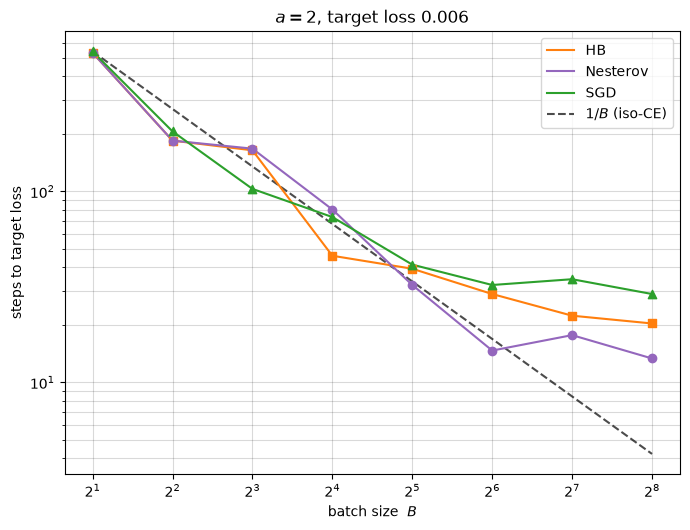

In [7]:
def plot_steps_sweep(results):
    colors = {'HB': 'tab:orange', 'Nesterov': 'tab:purple', 'SGD': 'tab:green'}
    markers = {'HB': 's', 'Nesterov': 'o', 'SGD': '^'}

    B_arr = np.array(results['B'], dtype=float)
    fig, ax = plt.subplots(figsize=(7.0, 5.4))

    for name in ALGOS:
        steps = np.array(results[name]['steps'], dtype=float)
        reached = np.array(results[name]['reached'], dtype=bool)
        ax.plot(B_arr, steps, color=colors[name], label=name, zorder=2)
        ax.scatter(B_arr[reached], steps[reached], marker=markers[name],
                   color=colors[name], zorder=3)
        ax.scatter(B_arr[~reached], steps[~reached], marker=markers[name],
                   facecolors='none', edgecolors=colors[name], zorder=3)

    # 1/B reference anchored at the smallest-batch SGD point
    anchor_steps = float(results['SGD']['steps'][0])
    B0 = B_arr[0]
    ref = anchor_steps * (B0 / B_arr)
    ax.plot(B_arr, ref, 'k--', alpha=0.7, label=r'$1/B$ (iso-CE)', zorder=1)

    ax.set_xscale('log', base=2)
    ax.set_yscale('log')
    ax.set_xlabel('batch size  $B$')
    ax.set_ylabel('steps to target loss')
    ax.set_title(rf'$a={BETA:g}$, target loss ${TARGET_LOSS:g}$')
    ax.grid(True, which='both', color=(0, 0, 0, 0.15))
    ax.legend()
    plt.tight_layout()
    plt.show()

plot_steps_sweep(RESULTS)

## Notes

Expected behavior (paper Figure 1, right panel):

- All curves hug the $1/B$ line at small $B$ (linear-scaling window), then flatten toward a serial-step floor — the elbow is the **critical batch size**.
- For the fast-decaying spectrum, ASGD (Nesterov) should reach a lower serial floor than HB, but peel off the $1/B$ line *earlier* (shorter linear window).

Tuning knobs if the shape looks wrong:

- **Curves flat everywhere / hollow markers at small $B$**: `K_MAX` too small or `TARGET_LOSS` too low — the small batches cannot reach the target. Raise `K_MAX` or `TARGET_LOSS`.
- **No visible elbow**: extend `B_EXPONENTS` to larger $B$, or lower `TARGET_LOSS` so the serial floor becomes visible.
- **Momentum never wins**: widen `ONE_MINUS_RHO_GRID` toward smaller $1-\rho$ (higher momentum) and `ETA_GRID` upward.

To add the slow-decaying panel, rerun with `BETA=0.9` and a larger `TARGET_LOSS` (the noise floor is higher), then place the two axes side by side.
- **Momentum shows hollow points at the smallest $B$**: expected — the stochastic noise floor of HB/NAG at tiny batch sits above the target, so they cannot reach it. Momentum needs a larger batch; this is part of the story, not a bug.
